# IMPORT

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import folium
import csv
import json
import os

# DEFINE FOLDERS

In [2]:
JSON_INPUT_FOLDER = Path("correlated_data_json")
DATASET_INPUT_FOLDER = Path("correlated_data_csv")
DATASET_OUTPUT_FOLDER = Path("clean_data_csv")
DELETED_STATIONS_FOLDER = Path("deleted_stations")
MAP_FOLDER = Path("maps")

folders = [JSON_INPUT_FOLDER, DATASET_INPUT_FOLDER, DATASET_OUTPUT_FOLDER, DELETED_STATIONS_FOLDER, MAP_FOLDER]
for folder in folders:
    folder.mkdir(parents=True, exist_ok=True)

# DEFINE CONSTANTS

In [3]:
REMAKE_CSV = False # To get the dataset from json files(will be saved in a csv file)
CSV_FILE_NAME = "correlated_data" #To save the dataset from json to csv/to get the dataset from csv
FINAL_CSV_FILE_NAME = "final_clean_data" # The prepared dataset


# DEFINE FUNCS

In [4]:
def print_df(dataframe):
    print("=========================================")
    print(f"Shape: \nrows:     {dataframe.shape[0]}\nfeatures: {dataframe.shape[1]}")
    
    data_size_bytes = dataframe.memory_usage(deep=True).sum()
    data_size_mb = data_size_bytes / (1024**2)
    print(f"Dataframe size: {data_size_bytes} bytes ({data_size_mb:.2f} MB)")

    print("-----------------------")
    display(dataframe.dtypes)
    print("-----------------------")
    display(dataframe.describe())
    print("=========================================")

MISSING_STRINGS = {"", "na", "n/a", "null", "none", "nan", "-"}
def rows_with_missing(df):
    mask = df.isna().any(axis=1)

    for col in df.columns:
        if df[col].dtype == object:
            col_str = df[col].str.strip().str.lower()
            mask |= col_str.isin(MISSING_STRINGS)

    return df[mask]


def print_missing(df, max_rows=10):
    print("=========================================")
    display(df.isna().sum().sort_values(ascending=False))
    print("-----------------------")

    missing = rows_with_missing(df)

    display(missing.head(max_rows))
    print(f"Missing rows (total): {len(missing)}")
    print("=========================================")



# IF WANT TO REMAKE CSV FILE FROM JSON FILES

In [5]:
CHUNK_SIZE = 50_000   # chunk size to save each time to CSV_FILE_NAME, so the memory doesn't explode
first_write = True

csv_path = os.path.join(DATASET_INPUT_FOLDER, f"{CSV_FILE_NAME}.csv")
total_file_num = len(os.listdir(JSON_INPUT_FOLDER))

if REMAKE_CSV:
    for file_idx, filename in enumerate(os.listdir(JSON_INPUT_FOLDER), start=1):
        if not filename.endswith(".json"):
            continue

        path = os.path.join(JSON_INPUT_FOLDER, filename)

        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)

        rows = []

        for entry in data:
            row = {}

            # Station fields
            fields = entry.get("fields", {})
            for key, value in fields.items():
                if key == "coordonnees_geo" and isinstance(value, list) and len(value) == 2:
                    row["latitude"] = value[0]
                    row["longitude"] = value[1]
                else:
                    row[key] = value

            # Weather fields
            weather = entry.get("weather", {})
            if "time" in weather:
                row["weather_time"] = weather["time"]

            for key, value in weather.items():
                if key != "time":
                    row[f"weather_{key}"] = value

            row["source_file"] = filename
            rows.append(row)

            # Write chunk
            if len(rows) >= CHUNK_SIZE:
                df_chunk = pd.DataFrame(rows)
                df_chunk.to_csv(
                    csv_path,
                    mode="w" if first_write else "a",
                    header=first_write,
                    index=False,
                    encoding="utf-8"
                )
                first_write = False
                rows.clear()

        # Flush remaining rows of this file
        if rows:
            df_chunk = pd.DataFrame(rows)
            df_chunk.to_csv(
                csv_path,
                mode = "w" if first_write else "a",
                header = first_write,
                index = False,
                encoding="utf-8"
            )
            first_write = False

        if file_idx % 100 == 0:
            print(f"{file_idx}/{total_file_num} JSON files processed")

    print("CSV generation finished.")

# LOAD DATA

In [6]:
df = pd.read_csv(f"{DATASET_INPUT_FOLDER}/{CSV_FILE_NAME}.csv")
df.head(5)

C:\Users\emirh\AppData\Local\Temp\ipykernel_22232\226569353.py:1: DtypeWarning: Columns (2,3,4,5,8,9,14,16) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(f"{DATASET_INPUT_FOLDER}/{CSV_FILE_NAME}.csv")


,name,stationcode,ebike,mechanical,latitude,longitude,duedate,numbikesavailable,numdocksavailable,capacity,...,is_returning,code_insee_commune,weather_time,weather_interval,weather_temperature_2m,weather_is_day,weather_wind_speed_10m,weather_wind_direction_10m,weather_weather_code,source_file
0,Cassini - Denfert-Rochereau,14111,2,0,48.837526,2.336035,2025-11-04T03:25:04+00:00,2.0,22,25,...,OUI,75056,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
1,Basilique,32017,5,1,48.936269,2.358867,2025-11-04T03:21:03+00:00,6.0,16,22,...,OUI,93066,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
2,Charonne - Robert et Sonia Delaunay,11104,1,1,48.855908,2.392571,2025-11-04T03:29:35+00:00,2.0,18,20,...,OUI,75056,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
3,Lacépède - Monge,5110,1,6,48.843893,2.351966,2025-11-04T03:30:23+00:00,7.0,15,23,...,OUI,75056,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json
4,Saint-Romain - Cherche-Midi,6108,2,2,48.847082,2.321375,2025-11-04T03:28:05+00:00,4.0,11,17,...,OUI,75056,2025-11-04T04:00,900.0,10.1,0.0,9.5,217.0,3.0,correlated_20251104_051241.json


In [7]:
print_df(df)
print_missing(df)

Shape: 
rows:     6070326
features: 23
Dataframe size: 5603664339 bytes (5344.07 MB)
-----------------------


name                            object
stationcode                      int64
ebike                           object
mechanical                      object
latitude                        object
longitude                       object
duedate                         object
numbikesavailable              float64
numdocksavailable               object
capacity                        object
is_renting                      object
is_installed                    object
nom_arrondissement_communes     object
is_returning                    object
code_insee_commune              object
weather_time                    object
weather_interval                object
weather_temperature_2m         float64
weather_is_day                 float64
weather_wind_speed_10m         float64
weather_wind_direction_10m     float64
weather_weather_code           float64
source_file                     object
dtype: object

-----------------------


,stationcode,numbikesavailable,weather_temperature_2m,weather_is_day,weather_wind_speed_10m,weather_wind_direction_10m,weather_weather_code
count,6.070326e+06,6.040351e+06,5.994689e+06,5.994689e+06,5.994689e+06,5.994689e+06,5.994689e+06
mean,1.892460e+04,1.246076e+01,1.207581e+01,3.969099e-01,9.491088e+00,1.935795e+02,1.517081e+01
std,1.241656e+04,1.106486e+01,5.189713e+01,7.507968e-01,4.263782e+00,6.609694e+01,2.632216e+01
min,0.000000e+00,0.000000e+00,-3.900000e+00,-7.000000e-01,0.000000e+00,4.000000e-01,0.000000e+00
25%,1.102900e+04,4.000000e+00,6.800000e+00,0.000000e+00,6.500000e+00,1.580000e+02,3.000000e+00
50%,1.700400e+04,9.000000e+00,9.200000e+00,0.000000e+00,9.300000e+00,1.830000e+02,3.000000e+00
75%,2.230400e+04,1.800000e+01,1.140000e+01,1.000000e+00,1.220000e+01,2.250000e+02,3.000000e+00
max,9.200800e+04,8.400000e+01,9.000000e+02,1.510000e+01,2.850000e+01,3.600000e+02,3.600000e+02


weather_weather_code           75637
weather_wind_direction_10m     75637
weather_wind_speed_10m         75637
weather_is_day                 75637
weather_temperature_2m         75637
weather_interval               75637
weather_time                   73541
source_file                    50171
nom_arrondissement_communes    48770
code_insee_commune             48770
is_returning                   48075
is_installed                   48075
is_renting                     48075
capacity                       30670
numdocksavailable              29975
numbikesavailable              29975
longitude                        695
latitude                         695
name                             695
stationcode                        0
duedate                            0
mechanical                         0
ebike                              0
dtype: int64

-----------------------


,name,stationcode,ebike,mechanical,latitude,longitude,duedate,numbikesavailable,numdocksavailable,capacity,...,is_returning,code_insee_commune,weather_time,weather_interval,weather_temperature_2m,weather_is_day,weather_wind_speed_10m,weather_wind_direction_10m,weather_weather_code,source_file
26,Caire - Dussoubs,2017,3,16,48.867853,2.349364,2025-11-04T03:25:15+00:00,19.0,20,40,...,OUI,75056,NaN,NaN,NaN,NaN,NaN,NaN,NaN,correlated_20251104_051241.json
37,Bellefond - Poissonnière,9001,7,6,48.877599,2.348464,2025-11-04T03:29:35+00:00,13.0,4,17,...,OUI,75056,NaN,NaN,NaN,NaN,NaN,NaN,NaN,correlated_20251104_051241.json
100,Enghien - Faubourg Poissonnière,10042,0,6,48.87242,2.348395,2025-11-04T03:30:22+00:00,6.0,23,33,...,OUI,75056,NaN,NaN,NaN,NaN,NaN,NaN,NaN,correlated_20251104_051241.json
111,Cossonnerie - Sébastopol,1119,1,4,48.861327,2.34942,2025-11-04T03:21:09+00:00,5.0,18,24,...,OUI,75056,NaN,NaN,NaN,NaN,NaN,NaN,NaN,correlated_20251104_051241.json
121,Rochechouart lamartine,9010,2,11,48.87672,2.344393,2025-11-04T03:29:21+00:00,13.0,9,24,...,OUI,75056,NaN,NaN,NaN,NaN,NaN,NaN,NaN,correlated_20251104_051241.json
204,Gare du Nord - Place de Valenciennes,10152,0,0,48.879089,2.354235,2025-07-08T08:17:37+00:00,0.0,0,0,...,NON,75056,NaN,NaN,NaN,NaN,NaN,NaN,NaN,correlated_20251104_051241.json
206,Petites Ecuries - Faubourg Poissonnière,10005,5,6,48.873972,2.348389,2025-11-04T03:28:34+00:00,11.0,4,17,...,OUI,75056,NaN,NaN,NaN,NaN,NaN,NaN,NaN,correlated_20251104_051241.json
253,Chabrol - d'Hauteville,10020,6,4,48.877018,2.351318,2025-11-04T03:29:56+00:00,10.0,1,11,...,OUI,75056,NaN,NaN,NaN,NaN,NaN,NaN,NaN,correlated_20251104_051241.json
286,Greneta - Sebastopol,2001,0,17,48.865242,2.351667,2025-11-04T03:26:08+00:00,17.0,14,32,...,OUI,75056,NaN,NaN,NaN,NaN,NaN,NaN,NaN,correlated_20251104_051241.json
309,Jeûneurs - Mulhouse,2110,2,2,48.868997,2.346925,2025-11-04T03:21:00+00:00,4.0,23,28,...,OUI,75056,NaN,NaN,NaN,NaN,NaN,NaN,NaN,correlated_20251104_051241.json


Missing rows (total): 75637


# RENAME FEATURES(COLUMNS)

In [8]:
feature_name_dict = {
    "name": "station_name",
    "stationcode": "station_code",
    "numbikesavailable": "total_bikes_now",
    "numdocksavailable": "total_bikes_taken",
    "nom_arrondissement_communes": "commune_name",
    "code_insee_commune": "postal_code",
    "weather_time": "timestamp",
    "weather_temperature_2m": "temperature",
    "weather_is_day": "is_day",
    "weather_wind_speed_10m": "wind_speed",
    "weather_wind_direction_10m": "wind_direction",
    "weather_weather_code": "weather_code"
}

df = df.rename(columns=feature_name_dict)

# CHECK

In [9]:
print(df.isna().sum().sort_values(ascending=False))

weather_code         75637
wind_direction       75637
wind_speed           75637
is_day               75637
temperature          75637
weather_interval     75637
timestamp            73541
source_file          50171
commune_name         48770
postal_code          48770
is_returning         48075
is_installed         48075
is_renting           48075
capacity             30670
total_bikes_taken    29975
total_bikes_now      29975
longitude              695
latitude               695
station_name           695
station_code             0
duedate                  0
mechanical               0
ebike                    0
dtype: int64


# DROP INVALID ROWS(DOESNT CONTAIN THE DATA FOR TOTAL_BIKES_NOW)

In [10]:
essential_data = [
    "station_name", 
    "station_code", 
    "postal_code", 
    "capacity", 
    "total_bikes_now", 
    "total_bikes_taken", 
    "timestamp"
]

df = df.dropna(subset=essential_data)

# RECHECK

In [11]:
print_missing(df)

source_file          2096
weather_code         2096
wind_direction       2096
wind_speed           2096
is_day               2096
temperature          2096
weather_interval     2096
commune_name            0
timestamp               0
postal_code             0
is_returning            0
station_name            0
station_code            0
is_renting              0
capacity                0
total_bikes_taken       0
total_bikes_now         0
duedate                 0
longitude               0
latitude                0
mechanical              0
ebike                   0
is_installed            0
dtype: int64

-----------------------


,station_name,station_code,ebike,mechanical,latitude,longitude,duedate,total_bikes_now,total_bikes_taken,capacity,...,is_returning,postal_code,timestamp,weather_interval,temperature,is_day,wind_speed,wind_direction,weather_code,source_file
319993,Hôpital Mondor,40001,11,0,48.798922,2.453745,2025-11-06T17:33:37+00:00,11.0,16,28.0,...,OUI,94028.0,correlated_20251106_193745.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN
320401,Conservatoire Marcel Dadi,40005,3,2,48.79009,2.453597,2025-11-06T17:36:12+00:00,5.0,21,26.0,...,OUI,94028.0,correlated_20251106_193745.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN
320703,Préfecture de Créteil,40007,9,10,48.78368,2.454471,2025-11-06T17:36:02+00:00,19.0,7,27.0,...,OUI,94028.0,correlated_20251106_193745.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN
320704,Stade de la Habette,40012,1,0,48.774397,2.466879,2025-11-06T17:31:28+00:00,1.0,15,16.0,...,OUI,94028.0,correlated_20251106_193745.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN
320705,Hôtel de Ville de Créteil,40013,6,12,48.776995,2.455255,2025-11-06T17:33:29+00:00,18.0,19,36.0,...,OUI,94028.0,correlated_20251106_193745.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN
320710,Créteil Pompadour,40008,17,2,48.773012,2.435166,2025-11-06T17:36:01+00:00,19.0,25,44.0,...,OUI,94028.0,correlated_20251106_193745.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN
320712,Iles de Loisirs de Créteil,40015,6,2,48.780258,2.445509,2025-11-06T17:36:43+00:00,8.0,15,24.0,...,OUI,94028.0,correlated_20251106_193745.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN
320727,Adrien Raynal - Verger,43101,0,0,48.743386,2.40256,2025-10-21T07:04:34+00:00,0.0,1,1.0,...,NON,94054.0,correlated_20251106_193745.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN
320728,Dr Calmette,43102,0,0,48.745457,2.408924,2025-10-22T06:18:49+00:00,0.0,1,1.0,...,NON,94054.0,correlated_20251106_193745.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN
320731,Gare RER les Saules - Chandigarh,43103,0,0,48.745654,2.416988,2025-10-21T07:03:08+00:00,0.0,1,1.0,...,NON,94054.0,correlated_20251106_193745.json,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing rows (total): 2096


# KEEPING THE USABLE COLUMNS

In [12]:
# Keep only useful columns
keep_cols = [
    "station_code",
    "latitude",
    "longitude",
    "capacity",
    "total_bikes_now",
    "total_bikes_taken",
    "timestamp",
    "temperature",
    "wind_speed",
    "wind_direction",
    "weather_code",
    "is_day",
]

df_cleaned = df[keep_cols].copy(deep=True)

print("Initial shape:", df_cleaned.shape)
print_df(df_cleaned)

Initial shape: (5996785, 12)
Shape: 
rows:     5996785
features: 12
Dataframe size: 1685305565 bytes (1607.23 MB)
-----------------------


station_code           int64
latitude              object
longitude             object
capacity              object
total_bikes_now      float64
total_bikes_taken     object
timestamp             object
temperature          float64
wind_speed           float64
wind_direction       float64
weather_code         float64
is_day               float64
dtype: object

-----------------------


,station_code,total_bikes_now,temperature,wind_speed,wind_direction,weather_code,is_day
count,5.996785e+06,5.996785e+06,5.994689e+06,5.994689e+06,5.994689e+06,5.994689e+06,5.994689e+06
mean,1.903078e+04,1.249982e+01,1.207581e+01,9.491088e+00,1.935795e+02,1.517081e+01,3.969099e-01
std,1.231781e+04,1.106209e+01,5.189713e+01,4.263782e+00,6.609694e+01,2.632216e+01,7.507968e-01
min,0.000000e+00,0.000000e+00,-3.900000e+00,0.000000e+00,4.000000e-01,0.000000e+00,-7.000000e-01
25%,1.103700e+04,4.000000e+00,6.800000e+00,6.500000e+00,1.580000e+02,3.000000e+00,0.000000e+00
50%,1.701000e+04,1.000000e+01,9.200000e+00,9.300000e+00,1.830000e+02,3.000000e+00,0.000000e+00
75%,2.230500e+04,1.800000e+01,1.140000e+01,1.220000e+01,2.250000e+02,3.000000e+00,1.000000e+00
max,9.200800e+04,8.400000e+01,9.000000e+02,2.850000e+01,3.600000e+02,3.600000e+02,1.510000e+01


# WEATHER TIME HANDLING

In [13]:
df_cleaned["timestamp"] = pd.to_datetime(df_cleaned["timestamp"], errors="coerce")

# Drop rows without time
df_cleaned = df_cleaned.dropna(subset=["timestamp"])

# Time features
df_cleaned["hour"] = df_cleaned["timestamp"].dt.hour
df_cleaned["day_of_week"] = df_cleaned["timestamp"].dt.dayofweek
df_cleaned["is_weekend"] = (df_cleaned["day_of_week"] >= 5).astype(int)

# Cyclical encoding
df_cleaned["sin_hour"] = np.sin(2 * np.pi * df_cleaned["hour"] / 24)
df_cleaned["cos_hour"] = np.cos(2 * np.pi * df_cleaned["hour"] / 24)

In [14]:
print_df(df_cleaned)

Shape: 
rows:     5974387
features: 17
Dataframe size: 1481299463 bytes (1412.68 MB)
-----------------------


station_code                  int64
latitude                     object
longitude                    object
capacity                     object
total_bikes_now             float64
total_bikes_taken            object
timestamp            datetime64[ns]
temperature                 float64
wind_speed                  float64
wind_direction              float64
weather_code                float64
is_day                      float64
hour                          int32
day_of_week                   int32
is_weekend                    int64
sin_hour                    float64
cos_hour                    float64
dtype: object

-----------------------


,station_code,total_bikes_now,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,5.974387e+06,5.974387e+06,5974387,5.974387e+06,5.974387e+06,5.974387e+06,5.974387e+06,5.974387e+06,5.974387e+06,5.974387e+06,5.974387e+06,5.974387e+06,5.974387e+06
mean,1.903980e+04,1.250318e+01,2025-11-28 15:02:10.500436224,9.058492e+00,9.521930e+00,1.942093e+02,1.463423e+01,3.647315e-01,1.142519e+01,2.984928e+00,2.841895e-01,1.083119e-02,2.566129e-03
min,1.001000e+03,0.000000e+00,2025-11-04 04:00:00,-3.900000e+00,0.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103800e+04,4.000000e+00,2025-11-16 05:45:00,6.800000e+00,6.500000e+00,1.580000e+02,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.701000e+04,1.000000e+01,2025-11-28 11:15:00,9.200000e+00,9.300000e+00,1.830000e+02,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,6.123234e-17
75%,2.230500e+04,1.800000e+01,2025-12-11 01:15:00,1.140000e+01,1.220000e+01,2.250000e+02,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,8.400000e+01,2025-12-23 12:15:00,1.950000e+01,2.850000e+01,3.600000e+02,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.231356e+04,1.106146e+01,NaN,3.769413e+00,4.237913e+00,6.531816e+01,2.447366e+01,4.813548e-01,6.925435e+00,2.003671e+00,4.510276e-01,7.072353e-01,7.068907e-01


# CHANGE FEATURE DATA TYPES FOR MEMORY OPTIMISATION

In [15]:
df_cleaned = df_cleaned.astype({
    "station_code": "uint32",
    "latitude": "float64",
    "longitude": "float64",
    "capacity": "uint8",
    "total_bikes_now": "uint8",
    "total_bikes_taken": "uint8",
    "temperature": "float16",
    "wind_speed": "float16",
    "wind_direction": "float16",
    "weather_code": "uint8",
    "is_day": "uint8",
    "hour": "uint8",
    "day_of_week": "uint8",
    "is_weekend": "uint8",
    "sin_hour": "float32",
    "cos_hour": "float32"
})

print_df(df_cleaned)
df_cleaned.head()

Shape: 
rows:     5974387
features: 17
Dataframe size: 346514446 bytes (330.46 MB)
-----------------------


station_code                 uint32
latitude                    float64
longitude                   float64
capacity                      uint8
total_bikes_now               uint8
total_bikes_taken             uint8
timestamp            datetime64[ns]
temperature                 float16
wind_speed                  float16
wind_direction              float16
weather_code                  uint8
is_day                        uint8
hour                          uint8
day_of_week                   uint8
is_weekend                    uint8
sin_hour                    float32
cos_hour                    float32
dtype: object

-----------------------


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\numpy\_core\_methods.py:51: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:731: RuntimeWarning: invalid value encountered in scalar divide
  the_mean = the_sum / count if count > 0 else np.nan
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\numpy\_core\_methods.py:51: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dt

,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,5.974387e+06,5.974387e+06,5.974387e+06,5.974387e+06,5.974387e+06,5.974387e+06,5974387,5.974387e+06,5.974387e+06,5974387.0,5.974387e+06,5.974387e+06,5.974387e+06,5.974387e+06,5.974387e+06,5.974387e+06,5.974387e+06
mean,1.903980e+04,4.885803e+01,2.341840e+00,3.186123e+01,1.250318e+01,1.842321e+01,2025-11-28 15:02:10.500436224,NaN,NaN,NaN,1.463423e+01,3.647315e-01,1.142519e+01,2.984928e+00,2.841895e-01,1.083118e-02,2.566127e-03
min,1.001000e+03,4.875696e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,2025-11-04 04:00:00,-3.900391e+00,0.000000e+00,1.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103800e+04,4.883692e+01,2.302569e+00,2.300000e+01,4.000000e+00,9.000000e+00,2025-11-16 05:45:00,6.800781e+00,6.500000e+00,158.0,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.701000e+04,4.885830e+01,2.343996e+00,3.000000e+01,1.000000e+01,1.700000e+01,2025-11-28 11:15:00,9.203125e+00,9.296875e+00,183.0,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,6.123234e-17
75%,2.230500e+04,4.887954e+01,2.379841e+00,3.800000e+01,1.800000e+01,2.500000e+01,2025-12-11 01:15:00,1.139844e+01,1.220312e+01,225.0,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,4.895757e+01,2.538242e+00,1.050000e+02,8.400000e+01,1.000000e+02,2025-12-23 12:15:00,1.950000e+01,2.850000e+01,360.0,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.231356e+04,3.229043e-02,5.851163e-02,1.262226e+01,1.106146e+01,1.239330e+01,NaN,0.000000e+00,0.000000e+00,0.0,2.447366e+01,4.813548e-01,6.925435e+00,2.003671e+00,4.510276e-01,7.071720e-01,7.092665e-01


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\io\formats\format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,timestamp,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
0,14111,48.837526,2.336035,25,2,22,2025-11-04 04:00:00,10.101562,9.5,217.0,3,0,4,1,0,0.866025,0.5
1,32017,48.936269,2.358867,22,6,16,2025-11-04 04:00:00,10.101562,9.5,217.0,3,0,4,1,0,0.866025,0.5
2,11104,48.855908,2.392571,20,2,18,2025-11-04 04:00:00,10.101562,9.5,217.0,3,0,4,1,0,0.866025,0.5
3,5110,48.843893,2.351966,23,7,15,2025-11-04 04:00:00,10.101562,9.5,217.0,3,0,4,1,0,0.866025,0.5
4,6108,48.847082,2.321375,17,4,11,2025-11-04 04:00:00,10.101562,9.5,217.0,3,0,4,1,0,0.866025,0.5


# DETECTING THE DUPLICATE ROWS(MULTIPLE ROWS FOR THE SAME (STATION, TIMESTAMP) COUPLES)

In [16]:
dup_mask = df_cleaned.duplicated(
    subset=["station_code", "timestamp"],
    keep=False
)

print(f"Duplicate rows: {dup_mask.sum()}")

display(
    df_cleaned.loc[dup_mask]
    .groupby(["station_code", "timestamp"])
    .size()
    .rename("dup_count")
    .sort_values(ascending=False)
    .head(10)
)


Duplicate rows: 19678


station_code  timestamp          
17111         2025-11-07 03:45:00    4
15023         2025-11-07 03:45:00    4
15019         2025-11-07 04:00:00    4
26003         2025-11-07 03:45:00    4
15020         2025-11-07 03:45:00    4
              2025-11-07 04:00:00    4
26002         2025-11-07 04:00:00    4
              2025-11-07 03:45:00    4
15021         2025-11-07 03:45:00    4
              2025-11-07 04:00:00    4
Name: dup_count, dtype: int64

# SET THE AGGREGATION RULES

In [17]:
agg_rules = {
    "latitude": "first",
    "longitude": "first",
    "capacity": "first",
    "total_bikes_now": "mean",
    "total_bikes_taken": "mean",
    "temperature": "mean",
    "wind_speed": "mean",
    "wind_direction": "mean",
    "weather_code": "first",
    "is_day": "first",
    "hour": "first",
    "day_of_week": "first",
    "is_weekend": "first",
    "sin_hour": "first",
    "cos_hour": "first",
}


# APPLY AGGREGATION RULES

In [18]:
before = len(df_cleaned)

df_cleaned = (
    df_cleaned
    .groupby(["station_code", "timestamp"], as_index=False)
    .agg(agg_rules)
)

after = len(df_cleaned)

print("Rows before:", before)
print("Rows after :", after)
print("Duplicates removed:", before - after)


Rows before: 5974387
Rows after : 5961565
Duplicates removed: 12822


# CHECK IF THERE ARE STILL DUPLICATES

In [19]:
assert not df_cleaned.duplicated(
    ["station_code", "timestamp"]
).any()
# No error means no duplicates

# HISTOGRAM OF ROWS

In [20]:
df_counts = df_cleaned["station_code"].value_counts().reset_index()
df_counts.columns = ["station_code", "count"]
print(df_counts)

      station_code  count
0            42303   3989
1            42304   3989
2            32020   3989
3            32021   3989
4            32022   3989
...            ...    ...
1499          8203   2494
1500         22209   1665
1501          8204   1335
1502         43203     76
1503         35010      3

[1504 rows x 2 columns]


count
3         1
76        1
1335      1
1665      1
2494      1
2523      1
2557      1
2560      1
2640      1
2859      1
2863      1
2864      1
3116      1
3177      1
3184      1
3432      1
3458      1
3464      1
3479      1
3484      1
3711      1
3917      1
3932      1
3938      1
3947      1
3956      1
3957      1
3962      1
3967      1
3974      6
3975     11
3976     46
3977      2
3978     34
3979     36
3980    185
3981     71
3982    153
3983    190
3984    284
3985    130
3986    178
3987     90
3988     32
3989     27
Name: count, dtype: int64


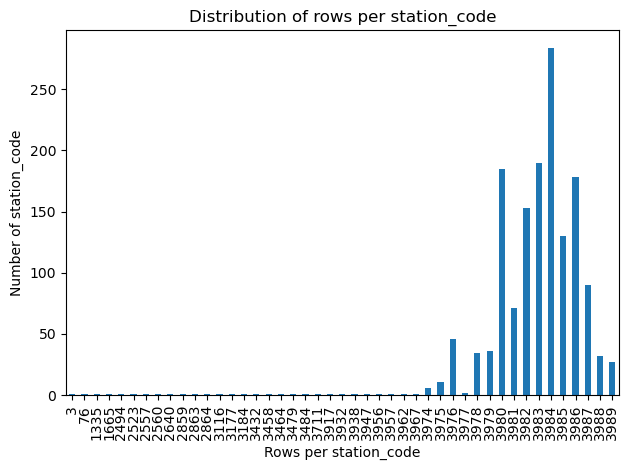

In [21]:
counts = df_cleaned["station_code"].value_counts()   # index=station_code, value=#rows
count_distribution = counts.value_counts().sort_index()
print(f"{count_distribution}")
count_distribution.plot(kind="bar")
plt.xlabel("Rows per station_code")
plt.ylabel("Number of station_code")
plt.title("Distribution of rows per station_code")
plt.tight_layout()
plt.show()

# MAKE THE MAP BEFORE DELETING STATIONS

In [22]:
def save_unique_stations_map_html(
    df,
    out_html="idf_stations",
    station_col="station_code",
    lat_col="latitude",
    lon_col="longitude",
    radius=0.01,               
    color="red",
    fill_opacity=0.8,
    zoom_start=10,
    tiles="CartoDB positronNoLabels",
):
    # Keep only needed cols, drop missing coords
    d = df[[station_col, lat_col, lon_col]].dropna(subset=[lat_col, lon_col])

    # Keep one row per station (huge speedup vs millions of rows)
    d = d.drop_duplicates(subset=[station_col], keep="first")

    # Ensure numeric
    d[lat_col] = d[lat_col].astype(float)
    d[lon_col] = d[lon_col].astype(float)

    # Center map
    center_lat = float(d[lat_col].mean())
    center_lon = float(d[lon_col].mean())

    # Minimal basemap
    m = folium.Map(location=[center_lat, center_lon], zoom_start=zoom_start, tiles=tiles)

    # Plot points
    for code, la, lo in zip(d[station_col], d[lat_col], d[lon_col]):
        folium.CircleMarker(
            location=[la, lo],
            radius=radius,
            color=color,
            fill=True,
            fill_color=color,
            fill_opacity=fill_opacity,
            tooltip=str(code),
        ).add_to(m)
    out_path = f"{MAP_FOLDER}/{out_html}.html"
    m.save(out_path)
    return out_path, len(d)


In [23]:
html_path, n = save_unique_stations_map_html(df_cleaned, out_html="idf_stations_before", radius=0.01)
print("Saved:", html_path, "| stations mapped:", n)

Saved: maps/idf_stations_before.html | stations mapped: 1504


# DETECT BROKEN STATIONS

In [24]:
MIN_ROWS = counts.quantile(0.05)   # up to ~5% of the stations at the bottom can be deleted

cols = ["total_bikes_now", "total_bikes_taken"]

station_stats = (
    df_cleaned
    .groupby("station_code")[cols]
    .agg(["count", "mean", "std"])
)


rule_few_rows = station_stats[("total_bikes_now", "count")] < MIN_ROWS

rule_now_bad = (
    station_stats[("total_bikes_now", "std")].isna() |
    (station_stats[("total_bikes_now", "std")] < 0.1) |
    (station_stats[("total_bikes_now", "mean")] < 0.5)
)

rule_taken_bad = (
    station_stats[("total_bikes_taken", "std")].isna() |
    (station_stats[("total_bikes_taken", "std")] < 0.1) |
    (station_stats[("total_bikes_taken", "mean")] < 0.5)
)

bad_stations = station_stats[
    rule_few_rows | rule_now_bad | rule_taken_bad
].index

print(rule_few_rows.sum(), "stations removed by row count")
print(rule_now_bad.sum(), "stations removed by bikes_now stats")
print(rule_taken_bad.sum(), "stations removed by bikes_taken stats")
print(f"Stations to remove: {len(bad_stations)}")

good_stations = df_cleaned["station_code"].unique()
good_stations = [s for s in good_stations if s not in bad_stations]

print(f"Stations to keep: {len(good_stations)}")


46 stations removed by row count
26 stations removed by bikes_now stats
19 stations removed by bikes_taken stats
Stations to remove: 66
Stations to keep: 1438


# REMOVE THE BROKEN STATIONS

In [25]:
print_df(df_cleaned)

df_kept = df_cleaned[df_cleaned["station_code"].isin(good_stations)].copy()

print_df(df_kept)

Shape: 
rows:     5961565
features: 17
Dataframe size: 405386552 bytes (386.61 MB)
-----------------------


station_code                 uint32
timestamp            datetime64[ns]
latitude                    float64
longitude                   float64
capacity                      uint8
total_bikes_now             float64
total_bikes_taken           float64
temperature                 float32
wind_speed                  float32
wind_direction              float16
weather_code                  uint8
is_day                        uint8
hour                          uint8
day_of_week                   uint8
is_weekend                    uint8
sin_hour                    float32
cos_hour                    float32
dtype: object

-----------------------


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\numpy\_core\_methods.py:51: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:731: RuntimeWarning: invalid value encountered in scalar divide
  the_mean = the_sum / count if count > 0 else np.nan
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)


,station_code,timestamp,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,5.961565e+06,5961565,5.961565e+06,5.961565e+06,5.961565e+06,5.961565e+06,5.961565e+06,5.961565e+06,5.961565e+06,5961565.0,5.961565e+06,5.961565e+06,5.961565e+06,5.961565e+06,5.961565e+06,5.961565e+06,5.961565e+06
mean,1.903916e+04,2025-11-28 16:05:54.789673216,4.885803e+01,2.341839e+00,3.186153e+01,1.250177e+01,1.842472e+01,9.055334e+00,9.528840e+00,NaN,1.466059e+01,3.654401e-01,1.144047e+01,2.983568e+00,2.848007e-01,9.253751e-03,1.449124e-03
min,1.001000e+03,2025-11-04 04:00:00,4.875696e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.900391e+00,0.000000e+00,1.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103800e+04,2025-11-16 07:30:00,4.883692e+01,2.302569e+00,2.300000e+01,4.000000e+00,9.000000e+00,6.800781e+00,6.500000e+00,159.0,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.701000e+04,2025-11-28 12:45:00,4.885830e+01,2.343996e+00,3.000000e+01,1.000000e+01,1.700000e+01,9.203125e+00,9.296875e+00,184.0,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,6.123234e-17
75%,2.230500e+04,2025-12-11 01:30:00,4.887954e+01,2.379841e+00,3.800000e+01,1.800000e+01,2.500000e+01,1.139844e+01,1.229688e+01,225.0,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,2025-12-23 12:15:00,4.895757e+01,2.538242e+00,1.050000e+02,8.400000e+01,1.000000e+02,1.950000e+01,2.850000e+01,360.0,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.231344e+04,NaN,3.228980e-02,5.851038e-02,1.262242e+01,1.106198e+01,1.239279e+01,3.760635e+00,4.219884e+00,0.0,2.449332e+01,4.815534e-01,6.923702e+00,2.005108e+00,4.513195e-01,7.068146e-01,7.071607e-01


Shape: 
rows:     5727820
features: 17
Dataframe size: 435314320 bytes (415.15 MB)
-----------------------


station_code                 uint32
timestamp            datetime64[ns]
latitude                    float64
longitude                   float64
capacity                      uint8
total_bikes_now             float64
total_bikes_taken           float64
temperature                 float32
wind_speed                  float32
wind_direction              float16
weather_code                  uint8
is_day                        uint8
hour                          uint8
day_of_week                   uint8
is_weekend                    uint8
sin_hour                    float32
cos_hour                    float32
dtype: object

-----------------------


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\numpy\_core\_methods.py:51: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:731: RuntimeWarning: invalid value encountered in scalar divide
  the_mean = the_sum / count if count > 0 else np.nan
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)


,station_code,timestamp,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,5.727820e+06,5727820,5.727820e+06,5.727820e+06,5.727820e+06,5.727820e+06,5.727820e+06,5.727820e+06,5.727820e+06,5727820.0,5.727820e+06,5.727820e+06,5.727820e+06,5.727820e+06,5.727820e+06,5.727820e+06,5.727820e+06
mean,1.910681e+04,2025-11-28 16:01:01.556560896,4.885768e+01,2.340860e+00,3.215019e+01,1.270608e+01,1.848219e+01,9.059355e+00,9.513637e+00,NaN,1.466086e+01,3.654371e-01,1.144043e+01,2.983484e+00,2.847713e-01,9.244189e-03,1.442974e-03
min,1.001000e+03,2025-11-04 04:00:00,4.875740e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.900391e+00,0.000000e+00,1.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,1.103800e+04,2025-11-16 07:00:00,4.883638e+01,2.302116e+00,2.300000e+01,4.000000e+00,9.000000e+00,6.800781e+00,6.500000e+00,159.0,3.000000e+00,0.000000e+00,5.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,1.700600e+04,2025-11-28 12:45:00,4.885800e+01,2.343500e+00,3.000000e+01,1.000000e+01,1.700000e+01,9.203125e+00,9.296875e+00,184.0,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,6.123234e-17
75%,2.240600e+04,2025-12-11 01:30:00,4.887949e+01,2.378775e+00,3.800000e+01,1.800000e+01,2.500000e+01,1.139844e+01,1.220312e+01,225.0,3.000000e+00,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,9.200800e+04,2025-12-23 12:15:00,4.895757e+01,2.538242e+00,7.800000e+01,7.900000e+01,7.800000e+01,1.950000e+01,2.850000e+01,360.0,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,1.240661e+04,NaN,3.234566e-02,5.848738e-02,1.221877e+01,1.100742e+01,1.217755e+01,3.761442e+00,4.220595e+00,0.0,2.449415e+01,4.815526e-01,6.923655e+00,2.005049e+00,4.513055e-01,7.068182e-01,7.071439e-01


# BUILD THE FULL BUT EMPTY(FOR NOW) DATAFRAME

In [26]:
# Min / max timestamp per station
station_ranges = (
    df_kept
    .groupby("station_code")["timestamp"]
    .agg(["min", "max"])
)

dfs = []

for station, (start, end) in station_ranges.iterrows():
    full_index = pd.date_range(start, end, freq="15min")

    full_df = pd.DataFrame({
        "station_code": station,
        "timestamp": full_index
    })

    merged = full_df.merge(
        df_kept[df_kept["station_code"] == station],
        on=["station_code", "timestamp"],
        how="left"
    )

    dfs.append(merged)

df_full = pd.concat(dfs, ignore_index=True)

print("Rows after full timeline:", len(df_full))
print("Added rows:", len(df_full) - len(df_kept))


Rows after full timeline: 6813164
Added rows: 1085344


# DETECT MISSING ROWS

In [27]:
missing_rows = df_full[df_full["total_bikes_now"].isna()]

missing_per_station = (
    missing_rows
    .groupby("station_code")
    .size()
    .sort_values(ascending=False)
)

print("Stations with most missing rows:")
print(missing_per_station.head(10))

Stations with most missing rows:
station_code
20115    762
20048    762
23802    762
20017    762
20021    762
20022    762
20023    762
20027    762
20029    762
20035    762
dtype: int64


# FILL STATIC COLUMNS

In [28]:
static_cols = ["latitude", "longitude", "capacity"] # Will be the same for its own station

df_full[static_cols] = (
    df_full
    .groupby("station_code")[static_cols]
    .transform("first")
)

# FILL WEATHER DATA WITH MEAN

In [29]:
weather_cols = [
    "temperature",
    "wind_speed",
    "wind_direction",
    "weather_code",
    "is_day",
]

for col in weather_cols:
    df_full[col] = (
        df_full
        .groupby("station_code")[col]
        .transform(lambda x: x.fillna(x.mean()))
    )

c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\numpy\_core\_methods.py:51: RuntimeWarning: overflow encountered in reduce
  return umr_sum(a, axis, dtype, out, keepdims, initial, where)


# FILL BIKE DATA WITH INTERPOLATION

In [30]:
bike_cols = ["total_bikes_now", "total_bikes_taken"]

# Sort first
df_full = df_full.sort_values(["station_code", "timestamp"])

# Interpolate per station using timestamp as index
def interpolate_bikes(group):
    group = group.set_index("timestamp")  # DatetimeIndex required
    group[bike_cols] = group[bike_cols].interpolate(method="time")
    return group.reset_index()

df_full = df_full.groupby("station_code").apply(interpolate_bikes).reset_index(drop=True)

# Fill edges
df_full[bike_cols] = df_full[bike_cols].fillna(method="ffill").fillna(method="bfill")


C:\Users\emirh\AppData\Local\Temp\ipykernel_22232\2741860525.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_full = df_full.groupby("station_code").apply(interpolate_bikes).reset_index(drop=True)
C:\Users\emirh\AppData\Local\Temp\ipykernel_22232\2741860525.py:15: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df_full[bike_cols] = df_full[bike_cols].fillna(method="ffill").fillna(method="bfill")


# FILL THE REST OF THE TIME DATA

In [31]:
df_full["hour"] = df_full["timestamp"].dt.hour.astype("uint8")
df_full["day_of_week"] = df_full["timestamp"].dt.dayofweek.astype("uint8")
df_full["is_weekend"] = (df_full["day_of_week"] >= 5).astype("uint8")
df_full["sin_hour"] = np.sin(2 * np.pi * df_full["hour"] / 24).astype("float32")
df_full["cos_hour"] = np.cos(2 * np.pi * df_full["hour"] / 24).astype("float32")

# CHECK

In [32]:
print("Remaining NaNs per column:")
print(df_full.isna().sum())

print("Final rows:", len(df_full))
print("Final stations:", df_full["station_code"].nunique())

Remaining NaNs per column:
timestamp            0
station_code         0
latitude             0
longitude            0
capacity             0
total_bikes_now      0
total_bikes_taken    0
temperature          0
wind_speed           0
wind_direction       0
weather_code         0
is_day               0
hour                 0
day_of_week          0
is_weekend           0
sin_hour             0
cos_hour             0
dtype: int64
Final rows: 6813164
Final stations: 1438


# MAKE THE MAP AFTER DELETING/REFILLING

In [33]:
html_path, n = save_unique_stations_map_html(df_full, radius=0.01, out_html="idf_stations_removed_refilled")
print("Saved:", html_path, "| stations mapped:", n)

Saved: maps/idf_stations_removed_refilled.html | stations mapped: 1438


# SAVE THE BROKEN STATIONS IN A FILE

In [34]:
broken_station_path = f"{DELETED_STATIONS_FOLDER}/broken_stations.csv"
stats = df_cleaned[df_cleaned["station_code"].isin(bad_stations)].groupby("station_code")["total_bikes_now"].agg(["mean", "std"])

with open(broken_station_path, "w", newline="", encoding="utf-8") as csvfile:
    writer = csv.writer(csvfile)
    # header
    writer.writerow(["station_code", "mean_total_bikes_now", "std_total_bikes_now"])
    for station, row in stats.iterrows():
        writer.writerow([station, row["mean"], row["std"]])

print(f"Broken stations saved: {len(bad_stations)}")
print(f"Saved: {broken_station_path}")

Broken stations saved: 66
Saved: deleted_stations/broken_stations.csv


# CHECK

In [35]:
print(df_full.isna().sum().sort_values(ascending=False))

timestamp            0
wind_direction       0
sin_hour             0
is_weekend           0
day_of_week          0
hour                 0
is_day               0
weather_code         0
wind_speed           0
station_code         0
temperature          0
total_bikes_taken    0
total_bikes_now      0
capacity             0
longitude            0
latitude             0
cos_hour             0
dtype: int64


# DETAILS

In [36]:
print_df(df_full)

Shape: 
rows:     6813164
features: 17
Dataframe size: 633624384 bytes (604.27 MB)
-----------------------


timestamp            datetime64[ns]
station_code                  int64
latitude                    float64
longitude                   float64
capacity                    float64
total_bikes_now             float64
total_bikes_taken           float64
temperature                 float32
wind_speed                  float32
wind_direction              float16
weather_code                float64
is_day                      float64
hour                          uint8
day_of_week                   uint8
is_weekend                    uint8
sin_hour                    float32
cos_hour                    float32
dtype: object

-----------------------


c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:1487: RuntimeWarning: overflow encountered in cast
  return dtype.type(n)
c:\Users\emirh\miniconda3\envs\dalas\Lib\site-packages\pandas\core\nanops.py:731: RuntimeWarning: invalid value encountered in scalar divide
  the_mean = the_sum / count if count > 0 else np.nan


,timestamp,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,6813164,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06,6813164.0,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06
mean,2025-11-28 20:07:55.024496384,1.910666e+04,4.885768e+01,2.340862e+00,3.206682e+01,1.270231e+01,1.848661e+01,9.059315e+00,9.513692e+00,NaN,1.466091e+01,3.654372e-01,1.147328e+01,2.985671e+00,2.836673e-01,5.164926e-03,-2.571589e-03
min,2025-11-04 04:00:00,1.001000e+03,4.875793e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.900391e+00,0.000000e+00,1.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,2025-11-16 12:00:00,1.103800e+04,4.883638e+01,2.302116e+00,2.300000e+01,4.000000e+00,9.000000e+00,7.199219e+00,7.101562e+00,163.0,3.000000e+00,0.000000e+00,6.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,2025-11-28 20:15:00,1.700700e+04,4.885799e+01,2.343500e+00,3.000000e+01,1.000000e+01,1.700000e+01,9.121023e+00,9.327639e+00,196.0,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,-1.836970e-16
75%,2025-12-11 04:15:00,2.240600e+04,4.887949e+01,2.378775e+00,3.800000e+01,1.800000e+01,2.500000e+01,1.089844e+01,1.160156e+01,292.0,1.465930e+01,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,2025-12-23 12:15:00,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,7.900000e+01,7.800000e+01,1.950000e+01,2.850000e+01,inf,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,NaN,1.240638e+04,3.234350e-02,5.848978e-02,1.231946e+01,1.100028e+01,1.216745e+01,3.445165e+00,3.875041e+00,NaN,2.245898e+01,4.415338e-01,6.907650e+00,1.999949e+00,4.507773e-01,7.098246e-01,7.087166e-01


In [37]:
# We do this because the other dataframe has small datatypes which does not let compute well
df_tmp = df_full.copy()
for col in df_tmp.select_dtypes(include=['uint8', 'uint16', 'uint32', 'float16']):
    df_tmp[col] = df_tmp[col].astype('float32')

display(df_tmp.describe())
del df_tmp

,timestamp,station_code,latitude,longitude,capacity,total_bikes_now,total_bikes_taken,temperature,wind_speed,wind_direction,weather_code,is_day,hour,day_of_week,is_weekend,sin_hour,cos_hour
count,6813164,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06,6813164.0,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06,6.813164e+06
mean,2025-11-28 20:07:55.024496384,1.910666e+04,4.885768e+01,2.340862e+00,3.206682e+01,1.270231e+01,1.848661e+01,9.059315e+00,9.513692e+00,inf,1.466091e+01,3.654372e-01,1.147328e+01,2.985671e+00,2.836673e-01,5.164926e-03,-2.571589e-03
min,2025-11-04 04:00:00,1.001000e+03,4.875793e+01,2.165597e+00,0.000000e+00,0.000000e+00,0.000000e+00,-3.900391e+00,0.000000e+00,1.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,-1.000000e+00,-1.000000e+00
25%,2025-11-16 12:00:00,1.103800e+04,4.883638e+01,2.302116e+00,2.300000e+01,4.000000e+00,9.000000e+00,7.199219e+00,7.101562e+00,163.0,3.000000e+00,0.000000e+00,6.000000e+00,1.000000e+00,0.000000e+00,-7.071068e-01,-7.071068e-01
50%,2025-11-28 20:15:00,1.700700e+04,4.885799e+01,2.343500e+00,3.000000e+01,1.000000e+01,1.700000e+01,9.121023e+00,9.327639e+00,196.0,3.000000e+00,0.000000e+00,1.100000e+01,3.000000e+00,0.000000e+00,1.224647e-16,-1.836970e-16
75%,2025-12-11 04:15:00,2.240600e+04,4.887949e+01,2.378775e+00,3.800000e+01,1.800000e+01,2.500000e+01,1.089844e+01,1.160156e+01,292.0,1.465930e+01,1.000000e+00,1.700000e+01,5.000000e+00,1.000000e+00,7.071068e-01,7.071068e-01
max,2025-12-23 12:15:00,9.200800e+04,4.895757e+01,2.538242e+00,7.800000e+01,7.900000e+01,7.800000e+01,1.950000e+01,2.850000e+01,inf,9.500000e+01,1.000000e+00,2.300000e+01,6.000000e+00,1.000000e+00,1.000000e+00,1.000000e+00
std,NaN,1.240638e+04,3.234350e-02,5.848978e-02,1.231946e+01,1.100028e+01,1.216745e+01,3.445165e+00,3.875041e+00,NaN,2.245898e+01,4.415338e-01,6.874669e+00,1.999951e+00,4.509021e-01,7.098246e-01,7.087166e-01


In [39]:
print(df_full.isna().sum().sort_values(ascending=False))

timestamp            0
wind_direction       0
sin_hour             0
is_weekend           0
day_of_week          0
hour                 0
is_day               0
weather_code         0
wind_speed           0
station_code         0
temperature          0
total_bikes_taken    0
total_bikes_now      0
capacity             0
longitude            0
latitude             0
cos_hour             0
dtype: int64


# SAVE THE FINAL CLEAN DATASET

In [38]:
df_full.to_csv(f"{DATASET_OUTPUT_FOLDER}/{FINAL_CSV_FILE_NAME}.csv", index=False)
print(f"Clean dataset saved: {FINAL_CSV_FILE_NAME}.csv")

Clean dataset saved: final_clean_data.csv
